# Самостоятельная работа: RGB DCGAN для лиц Olivetti Faces

В этой работе нужно самостоятельно собрать и исследовать DCGAN для
генерации лиц. Olivetti Faces отличается от LFW: это небольшой набор
из 400 чёрно-белых лиц размером $64\times64$. Канал повторяется три
раза только для совместимости с RGB-архитектурой; новых цветовых
сведений такое преобразование не создаёт.

Все заголовки описывают этапы. Маркеры `TODO(student)` находятся
исключительно в коде и обозначают место самостоятельной реализации.

## Короткий сюжет опыта

Вы строите художника, который рисует лицо по карточке из 100 чисел, и
проверяющего, который отличает рисунок от фотографии. За одну итерацию
сначала учится проверяющий, а затем художник получает его замечания.
Каждая следующая ячейка создаёт одну нужную часть этой игры. Не
переходите дальше, пока контрольная точка текущего этапа не выполнена.

### Словарь перед первой реализацией

Параметры — числа внутри слоёв, которые можно менять. Прямой проход
создаёт картинку и ответ проверяющего. Потеря — одно число, описывающее
ошибку ответа. Градиент — подсказка, как немного изменить параметры.
`GradientTape` находит такие подсказки, а Adam применяет их к выбранной
сети.

## Этап 1. Конфигурация и назначение данных

**Цель:** определить воспроизводимый эксперимент. Доступны все
константы ниже. Метки субъектов Olivetti нельзя передавать в GAN:
генератор не классифицирует людей, а дискриминатор видит только
реальное или синтетическое изображение.

**Контрольная точка:** реальный пакет должен иметь форму
$(B,64,64,3)$, а шум — $(B,100)$.

`(B,64,64,3)` означает «B изображений, у каждого 64 строки, 64
столбца и три канала». Три одинаковых канала здесь нужны не для
создания цвета, а чтобы форма совпадала с учебной RGB-архитектурой.
Метка субъекта — подпись для человека, но не ответ для GAN.

In [1]:
# get_ipython нужен только для Jupyter: эта команда заставляет
# Matplotlib рисовать внутри ноутбука, без отдельного окна Figure.
from __future__ import annotations

from pathlib import Path
from IPython import get_ipython
shell = get_ipython()
if shell is not None:
    shell.run_line_magic('matplotlib', 'inline')
import matplotlib.pyplot as plt
import numpy as np
import tensorflow as tf
from sklearn.datasets import fetch_olivetti_faces

# Сначала зафиксируйте конфигурацию, затем seed — до загрузки и
# создания модели, чтобы срез данных, веса и шум можно было повторить.
SEED = 42
MAX_EXAMPLES = 400
IMAGE_SIZE = 64
CHANNELS = 3
NOISE_DIM = 100
BATCH_SIZE = 32
EPOCHS = 120
LEARNING_RATE = 2e-4
BETA_1 = 0.5
REAL_LABEL = 0.9
# В ARTIFACT_DIR сохраняются только изображения/графики эксперимента.
ARTIFACT_DIR = Path('artifacts/olivetti_face_gan_tensorflow')
ARTIFACT_DIR.mkdir(parents=True, exist_ok=True)
tf.keras.utils.set_random_seed(SEED)
print("TensorFlow:",tf.__version__,"GPU:",tf.config.list_physical_devices("GPU"))

TensorFlow: 2.21.0 GPU: [PhysicalDevice(name='/physical_device:GPU:0', device_type='GPU')]


## Этап 2. Получение Olivetti Faces и переход к RGB-форме

**Требуется:** загрузить набор с фиксированным `random_state`, взять
изображения формы $(N,64,64)$, добавить последнюю ось и повторить её
три раза. Затем преобразовать диапазон $[0,1]$ в $[-1,1]$ и создать
`tf.data.Dataset` из изображений без идентификаторов людей.

**Проверка:** `x_real.shape == (MAX_EXAMPLES, 64, 64, 3)`; все
значения конечны и принадлежат $[-1,1]$.

**Сначала → затем → проверить.** Сначала получите серое лицо в
`[0,1]`. Затем повторите канал и получите RGB-форму. После этого
переведите числа в `[-1,1]`: именно в этой шкале будет рисовать `tanh`
генератора. Наконец сформируйте `dataset` только из `x_real`; ID людей
в него не кладётся. Покажите одну картинку до обучения: это быстро
обнаружит перепутанную шкалу или оси.

In [2]:
faces=fetch_olivetti_faces(random_state=SEED)
subject_ids=faces.target[:MAX_EXAMPLES]
x_real=np.repeat(faces.images[:MAX_EXAMPLES,...,None],3,axis=-1).astype(np.float32)*2-1
dataset=tf.data.Dataset.from_tensor_slices(x_real).shuffle(len(x_real),seed=SEED).batch(BATCH_SIZE)
assert x_real.shape==(MAX_EXAMPLES,64,64,3) and np.isfinite(x_real).all()
assert x_real.min()>=-1 and x_real.max()<=1
print(x_real.shape,x_real.min(),x_real.max(),next(iter(dataset)).shape)

downloading Olivetti faces from https://ndownloader.figshare.com/files/5976027 to /root/scikit_learn_data
(400, 64, 64, 3) -1.0 1.0 (32, 64, 64, 3)


## Этап 3. Свёрточный генератор

**Требуется:** реализовать генератор, который преобразует
$(B,100)$ в $(B,64,64,3)$: `Dense(4·4·512)`, reshape и четыре
`Conv2DTranspose` с промежуточными BatchNormalization и ReLU. На
последнем слое используйте `tanh`.

**Контрольная точка:** диагностический проход выдаёт конечные значения
в диапазоне $[-1,1]$, а не плоский вектор пикселей.

Генератор сначала получает одну карточку из 100 чисел на лицо. Он
делает маленькую внутреннюю картинку, а затем несколько раз увеличивает
её. Транспонированная свёртка — не волшебное увеличение готовой
фотографии: она применяет обучаемые правила и создаёт новые пиксели.
`BatchNormalization` помогает числам внутри сети оставаться удобного
масштаба, а `tanh` ограничивает финальные RGB-значения.

In [3]:
def make_generator():
    L=tf.keras.layers
    layers=[L.Input((NOISE_DIM,)),L.Dense(4*4*512,use_bias=False,kernel_initializer=tf.keras.initializers.RandomNormal(stddev=0.02)),L.Reshape((4,4,512)),L.BatchNormalization(),L.ReLU()]
    for channels in (256,128,64):
        layers += [L.Conv2DTranspose(channels,4,strides=2,padding='same',use_bias=False,kernel_initializer=tf.keras.initializers.RandomNormal(stddev=0.02)),L.BatchNormalization(),L.ReLU()]
    layers += [L.Conv2DTranspose(3,4,strides=2,padding='same',activation='tanh',kernel_initializer=tf.keras.initializers.RandomNormal(stddev=0.02))]
    return tf.keras.Sequential(layers)
generator=make_generator(); fake=generator(tf.random.normal((BATCH_SIZE,NOISE_DIM)),training=False)
assert fake.shape==(BATCH_SIZE,64,64,3) and np.isfinite(fake.numpy()).all() and np.max(np.abs(fake.numpy()))<=1
print('G(z):',fake.shape)

G(z): (32, 64, 64, 3)


## Этап 4. Свёрточный дискриминатор и логиты

**Требуется:** собрать дискриминатор из свёрток со stride 2,
LeakyReLU, Dropout и завершающего `Dense(1)` **без sigmoid**. Его
выход — логит формы $(B,1)$. Поэтому в BCE надо указать
`from_logits=True`.

**Контрольная точка:** не проверяйте логиты на принадлежность
интервалу $(0,1)$: это свойство вероятности после sigmoid, но не
самого логита.

Логит — просто оценка до перевода в вероятность. Большой положительный
логит говорит «скорее настоящее», большой отрицательный — «скорее
синтетическое». `BinaryCrossentropy(from_logits=True)` сама выполняет
нужный перевод надёжнее, чем отдельный sigmoid. D не определяет, кто
изображён на лице: он отвечает только на вопрос об источнике картинки.

In [4]:
def make_discriminator():
    L=tf.keras.layers
    layers=[L.Input((64,64,3))]
    for channels in (64,128,256,512):
        layers += [L.Conv2D(channels,4,strides=2,padding='same',kernel_initializer=tf.keras.initializers.RandomNormal(stddev=0.02)),L.LeakyReLU(negative_slope=0.2),L.Dropout(0.3)]
    return tf.keras.Sequential(layers+[L.Flatten(),L.Dense(1)])
discriminator=make_discriminator()
score=discriminator(fake,training=False).numpy()
assert score.shape==(BATCH_SIZE,1) and np.isfinite(score).all()
print('D(G(z)):',score.shape,'G params:',generator.count_params(),'D params:',discriminator.count_params())

D(G(z)): (32, 1) G params: 3578627 D params: 2764737


## Этап 5. Раздельные шаги оптимизации

**Требуется:** реализовать два `GradientTape`. В шаге дискриминатора
используйте `stop_gradient(G(z))`, реальные цели 0.9 и синтетические
0. В шаге генератора используйте новую выборку шума и целевое значение
1; градиент должен пройти через дискриминатор к изображению, но
оптимизатор меняет только переменные генератора.

**Проверка:** обе потери — конечные скаляры; после каждого подшага
изменяется только соответствующий набор параметров.

**Сначала учится D.** Настоящие лица имеют цель 0.9, рисунки — 0.
`stop_gradient` превращает рисунок в «готовую картинку» именно для
этой фазы: обратная стрелка к G выключена. **Затем учится G.** Новый
шум создаёт новый рисунок, а его цель равна 1. D остаётся полезным
проверяющим, который сообщает направление улучшения, но второй
оптимизатор получает только веса G.

`training=False` у D означает «не включать его Dropout», а не «не
передавать замечание художнику». Стрелка градиента к G сохраняется;
она исчезла бы только при `stop_gradient` в этой второй фазе.

Здесь D возвращает логит $\ell$, то есть свободную оценку до
вероятности. Мысленно вероятность равна
$p=\sigma(\ell)=1/(1+e^{-\ell})$, а ошибка одной картинки и цели $y$
записывается так:

$$
\operatorname{BCE}(y,p)=-y\log p-(1-y)\log(1-p).
$$

`BinaryCrossentropy(from_logits=True)` получает логит и объединяет
sigmoid с этой формулой устойчиво; отдельный sigmoid перед loss был бы
неверным дублированием.

### Математический и API-контракт

**Сначала прочитайте маршрут одного пакета, а уже потом заполняйте
`TODO(student)`.**

![Два независимых обновления GAN: обучение дискриминатора, затем обучение генератора](assets/diagrams/gan_two_phase_training.svg)

На рисунке синие блоки — данные, зелёные — сети с параметрами, красные
— потери-скаляры. Ваш код будет создавать временные синие тензоры,
получать два красных числа и передавать Adam только пары градиентов с
зелёными параметрами. Ни шум, ни изображения, ни классовые метки лиц
не являются объектами оптимизации.

Пусть $\theta_G$ — все веса генератора, а $\theta_D$ — все веса
дискриминатора. Потеря — одно итоговое число. Её производная по весу
отвечает, в какую сторону слегка изменить этот вес; общий шаг имеет вид

$$
\theta\leftarrow\theta-\eta\nabla_\theta\mathcal L.
$$

В первой фазе составьте $\mathcal L_D$ из BCE настоящих лиц с целью
0.9 и синтетических с целью 0, после чего берите градиент только по
$\theta_D$. Во второй составьте
$\mathcal L_G=\operatorname{BCE}(1,D(G(\mathbf z_G)))$ и берите
градиент только по $\theta_G$. Шум $\mathbf z_G$ — новый вход, а не
параметр, который оптимизатор должен сохранять.

### Как `GradientTape` помогает выполнить математическое правило

![Жизненный цикл GradientTape от прямого прохода до обновления Adam](assets/diagrams/tensorflow_gradient_tape.svg)

`GradientTape` записывает прямой путь до одной потери. Пока активен
блок `with`, TensorFlow строит временный граф дифференцируемых операций
и автоматически наблюдает задействованные обучаемые `tf.Variable`.
Вызов `tape.gradient(loss, variables)` идёт по этому графу назад и
возвращает одну производную на каждый указанный вес; её форма совпадает
с формой этого веса. Наконец, `zip` формирует пары «производная, вес»,
а `apply_gradients` передаёт их Adam. Поэтому именно список переменных
в этом вызове определяет, что обновляется.

У обычного непостоянного tape есть один обратный проход: после
`gradient(...)` его запись освобождается. Не нужно вручную строить
якобианы всех RGB-пикселей и весов; TensorFlow эффективно передаёт их
действие на градиент скалярной потери.

В фазе G путь остаётся математически равным

$$
\frac{\partial\mathcal L_G}{\partial\theta_G}
=\frac{\partial\mathcal L_G}{\partial D}
\frac{\partial D}{\partial G}
\frac{\partial G}{\partial\theta_G}.
$$

Это **цепное правило**: изменение веса G меняет картинку, картинка
меняет ответ D, а ответ D меняет итоговую потерю. D участвует в этой
цепочке как измерительный прибор, но его веса не стоят в списке
`variables`, поэтому их поправка не применяется.

### Один мини-пакет: спецификация будущего TensorFlow-кода

В самостоятельной реализации используйте следующие математические
роли и имена. Ничего из этой таблицы не надо оптимизировать, кроме
параметров $\theta_G$ и $\theta_D$.

| Объект | Имя, которое следует завести | Форма | Что проверять |
| --- | --- | --- | --- |
| Настоящие лица $\mathbf x_{\rm real}$ | `real_images` | `(B,64,64,3)` | Значения `[-1,1]`, цель D — 0.9. |
| Шум D $\mathbf z_D$ | `discriminator_noise` | `(B,100)` | Это временный вход генератора. |
| Подделка для D | `fake_images` | `(B,64,64,3)` | После `stop_gradient`; цель D — 0. |
| Логиты D | `real_logits`, `fake_logits` | `(B,1)` | Могут быть любыми вещественными числами. |
| Потеря D | `d_loss` | скаляр | Градиент берётся по `discriminator.trainable_variables`. |
| Шум G $\mathbf z_G$ | `generator_noise` | `(B,100)` | Это новая независимая выборка. |
| Изображение G | `generated_images` | `(B,64,64,3)` | Не отсоединяется от графа. |
| Потеря G | `g_loss` | скаляр | Градиент берётся по `generator.trainable_variables`. |

**Контроль перед переходом к следующей ячейке.** Разделите в уме
объекты таблицы на данные, параметры и скаляры. `fake_images` после
`stop_gradient` всё ещё имеет форму `(B,64,64,3)` и те же пиксели, но
перестаёт быть путём к $\theta_G$ только в фазе D. Во второй фазе
`generated_images` нельзя отсоединять: иначе `g_loss` не сможет дать
генератору никакого замечания.

**Порядок, который надо увидеть в своём коде.** Сначала первый tape
должен закончиться `d_loss`; следующий вызов `gradient` получает только
список весов D. Потом создаётся второй tape и новый шум; он заканчивается
`g_loss`, а `gradient` получает только список весов G. `zip` не меняет
данные — он лишь соединяет производную правильной формы с её весом.
Только `apply_gradients` делает шаг Adam и действительно изменяет сеть.

Для проверки обратного пути используйте запись

$$
\nabla_{\theta_G}\mathcal L_G=
J_{G,\theta_G}^{\mathsf T}J_{D,\mathbf x}^{\mathsf T}
\nabla_{\ell}\mathcal L_G.
$$

Якобиан — таблица локальных влияний. TensorFlow не материализует
огромные якобианы для RGB-изображений, а вычисляет их нужное действие
на градиент ошибки автоматически во время `tape.gradient`.

In [5]:
LOGITS=True

import time, json
from IPython.display import display, Markdown

def make_step(generator, discriminator):
    bce = tf.keras.losses.BinaryCrossentropy(from_logits=LOGITS)
    opt_g = tf.keras.optimizers.Adam(LEARNING_RATE, beta_1=BETA_1)
    opt_d = tf.keras.optimizers.Adam(LEARNING_RATE, beta_1=BETA_1)
    @tf.function
    def d_step(real):
        z = tf.random.normal([tf.shape(real)[0], NOISE_DIM])
        fake = tf.stop_gradient(generator(z, training=False))
        with tf.GradientTape() as tape:
            r = discriminator(real, training=True)
            f = discriminator(fake, training=True)
            loss = 0.5*(bce(tf.ones_like(r)*REAL_LABEL,r)+bce(tf.zeros_like(f),f))
        tf.debugging.assert_all_finite(loss,'D loss')
        opt_d.apply_gradients(zip(tape.gradient(loss,discriminator.trainable_variables),discriminator.trainable_variables))
        return loss
    @tf.function
    def g_step(real):
        z = tf.random.normal([tf.shape(real)[0], NOISE_DIM])
        with tf.GradientTape() as tape:
            f = discriminator(generator(z, training=True), training=False)
            loss = bce(tf.ones_like(f),f)
        tf.debugging.assert_all_finite(loss,'G loss')
        opt_g.apply_gradients(zip(tape.gradient(loss,generator.trainable_variables),generator.trainable_variables))
        return loss
    def train_step(real):
        return d_step(real),g_step(real)
    return train_step,d_step,g_step

# Проверяем фазы на отдельной паре моделей, не меняя стартовые веса эксперимента.
g_test,d_test=make_generator(),make_discriminator()
_,ds,gs=make_step(g_test,d_test)
real=next(iter(dataset))
def snapshot(model): return [v.numpy().copy() for v in model.weights]
def unchanged(old,model): return all(np.array_equal(a,b.numpy()) for a,b in zip(old,model.weights))
g0,d0=snapshot(g_test),snapshot(d_test)
print('D loss (диагностика):',float(ds(real)))
assert unchanged(g0,g_test) and not unchanged(d0,d_test)
g0,d0=snapshot(g_test),snapshot(d_test)
print('G loss (диагностика):',float(gs(real)))
assert unchanged(d0,d_test) and not unchanged(g0,g_test)
print('Раздельное обновление подтверждено')
del g_test,d_test,ds,gs,_

D loss (диагностика): 0.6918696165084839
G loss (диагностика): 0.67033851146698
Раздельное обновление подтверждено


## Этап 6. Наблюдение генераций и выводы

**Требуется:** обучить DCGAN, сохранять сетку фиксированных шумовых
векторов через равные интервалы, построить обе истории потерь и
объяснить разнообразие либо коллапс мод. Не считайте идентификаторы
людей показателем качества GAN.

**Итоговая самопроверка:** шум `(B,100)`, изображения `(B,64,64,3)`,
логиты `(B,1)`, значения потерь конечны, метки субъектов не участвовали
в обучении.

Используйте один `fixed_noise` для всех сеток. Это одинаковые задания
для художника в начале и конце опыта; тогда видна работа обучения, а
не смена карточки. Для вывода на экран верните `[-1,1]` к `[0,1]`.
Линии потерь — полезный дневник, но не оценка красоты: смотрите на них
вместе с разнообразием лиц и отсутствием чёрных/одинаковых кадров.

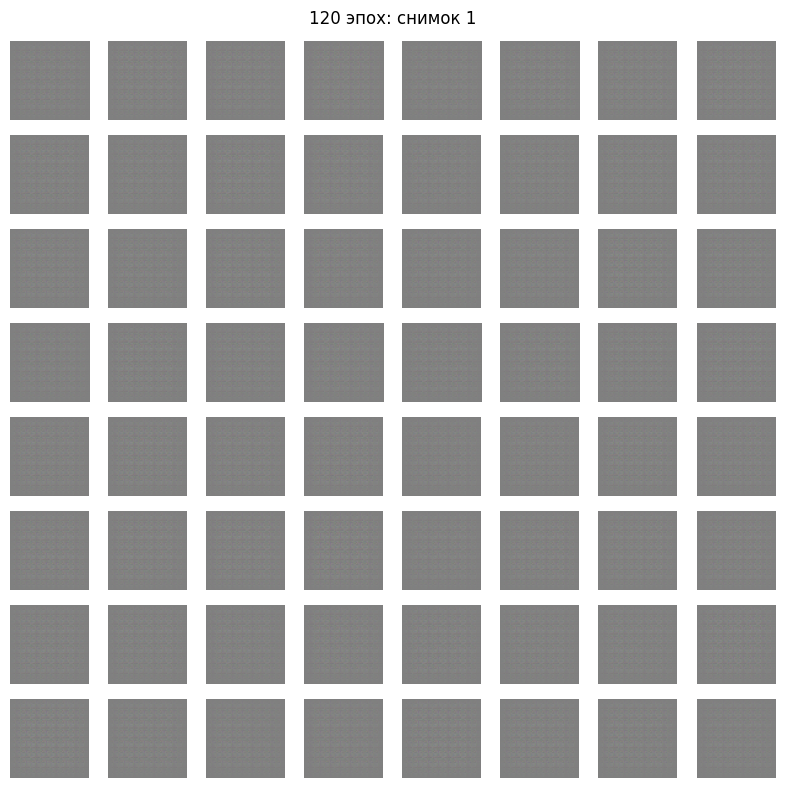

1/120: D=0.55137, G=0.32619


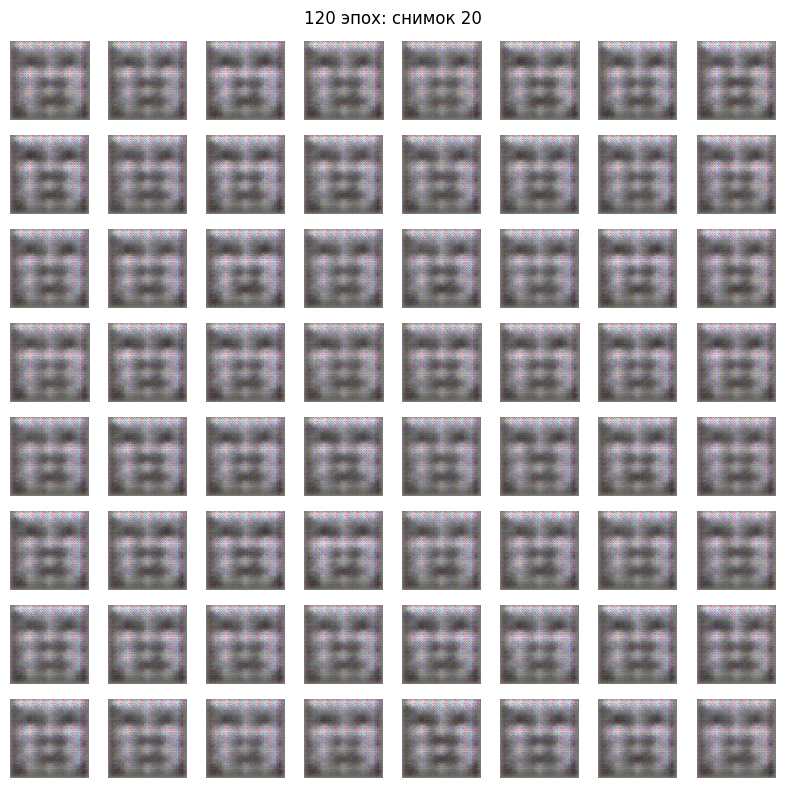

20/120: D=0.17528, G=0.01207


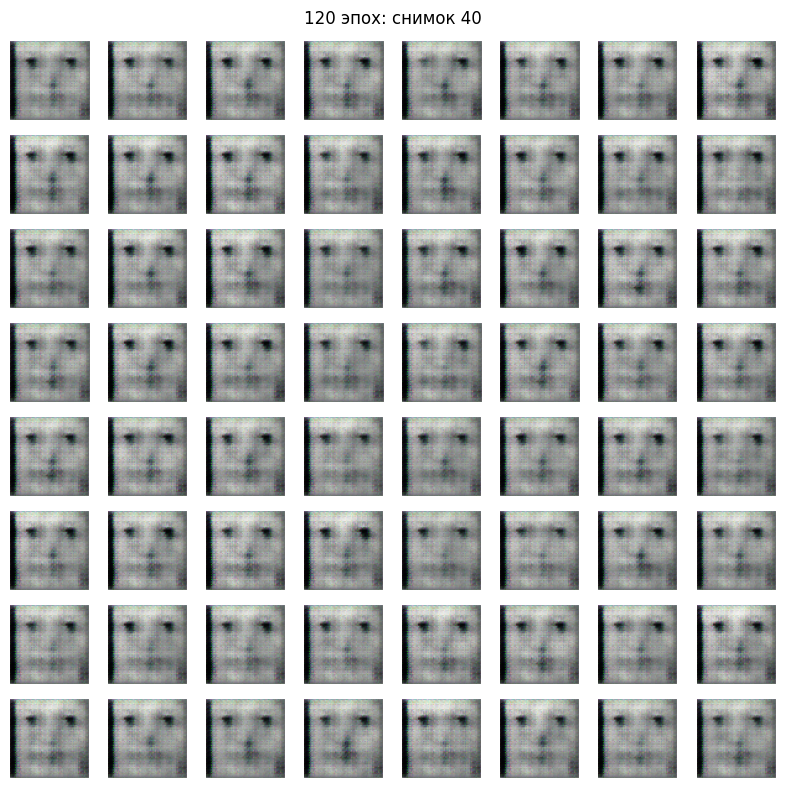

40/120: D=0.54571, G=1.97940


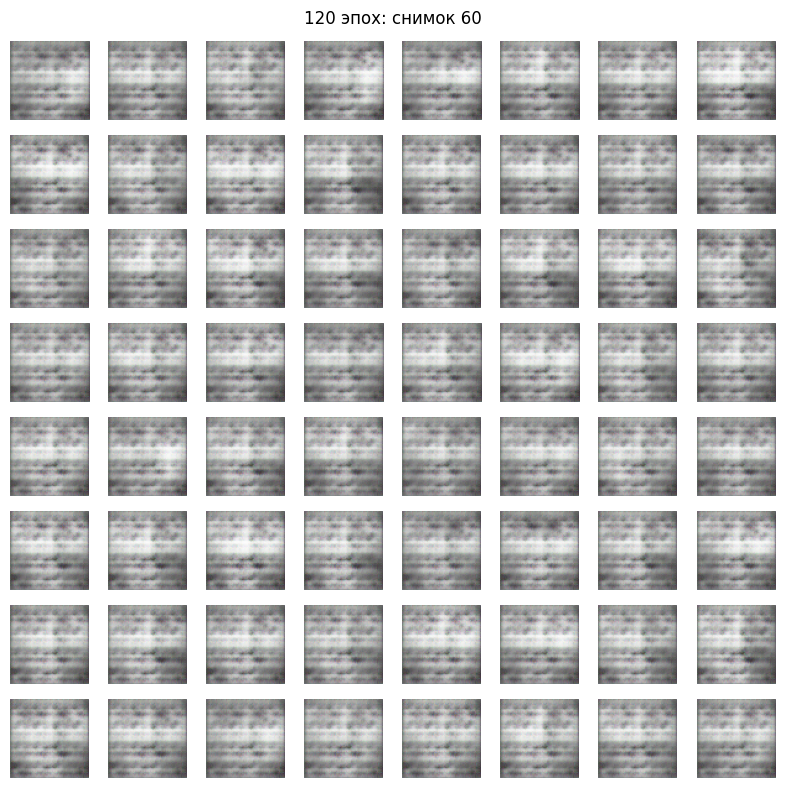

60/120: D=0.46650, G=2.47057


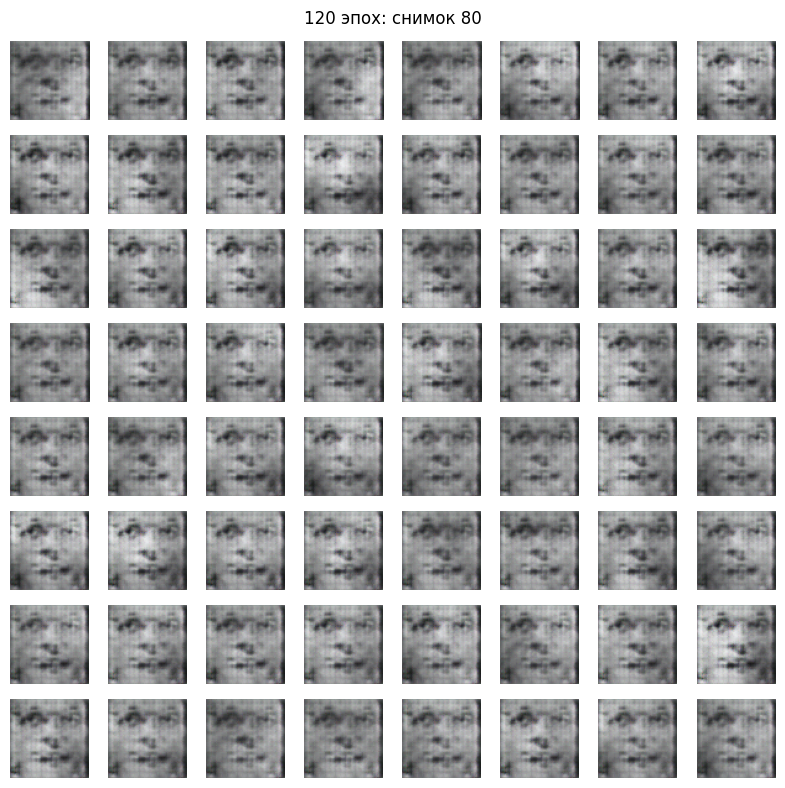

80/120: D=0.56549, G=1.48517


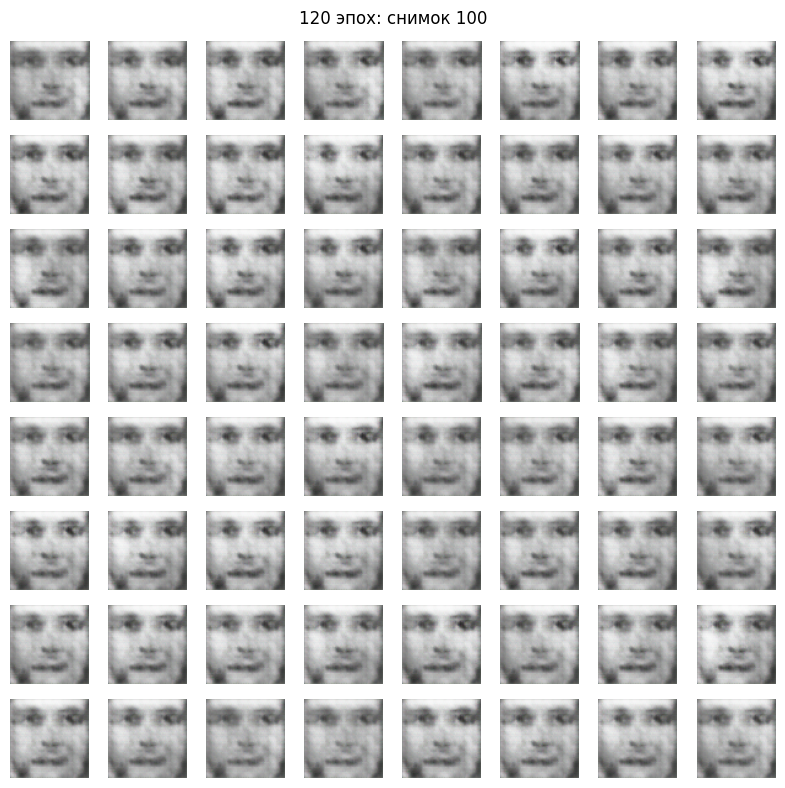

100/120: D=0.28714, G=0.18339


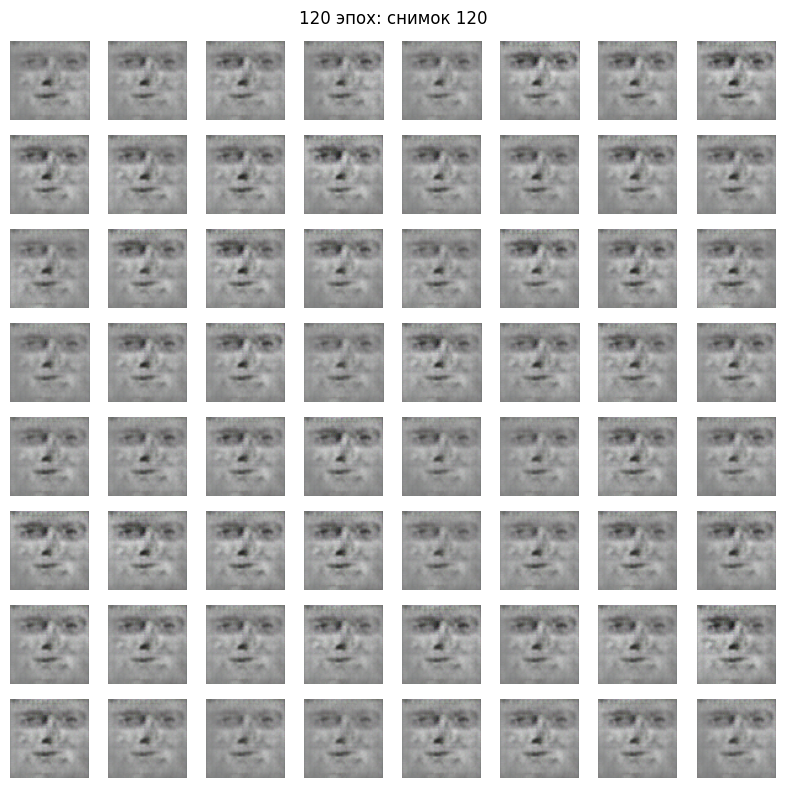

120/120: D=0.19402, G=0.16660


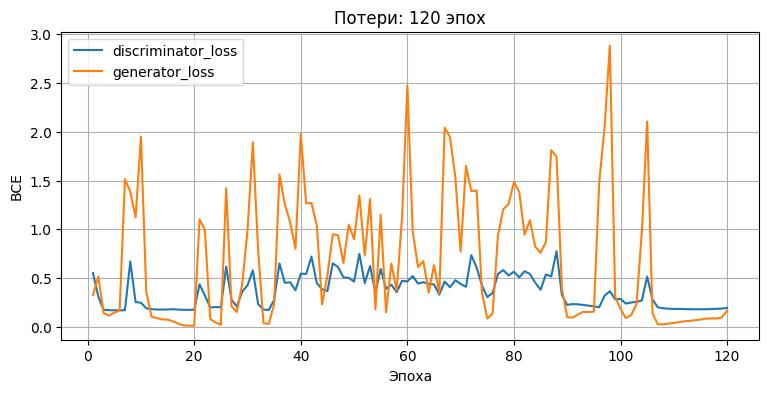

Устройство: [PhysicalDevice(name='/physical_device:GPU:0', device_type='GPU')]
N= 400 B= 32 lr= 0.0002 seed= 42
120: D 0.55137 → 0.19402; G 0.32619 → 0.16660; вариация 0.00309 → 0.04077; секунд 108.5


7569

In [6]:
RUNS=[EPOCHS]
GRID_SIZE=64
DISPLAY_SHAPE=(64,64,3)
BASE_DIR=ARTIFACT_DIR
TRAIN_IMAGES=x_real

fixed_noise=tf.random.stateless_normal((GRID_SIZE,NOISE_DIM),seed=[SEED,17])
results={}
for epochs in RUNS:
    tf.keras.backend.clear_session()
    tf.keras.utils.set_random_seed(SEED)
    generator,discriminator=make_generator(),make_discriminator()
    train_step,_,_=make_step(generator,discriminator)
    run_dir=BASE_DIR/f'epochs_{epochs}'
    run_dir.mkdir(parents=True,exist_ok=True)
    history={'discriminator_loss':[],'generator_loss':[],'diversity':[]}
    # Новый shuffle с тем же seed для каждого независимого запуска.
    train_data=tf.data.Dataset.from_tensor_slices(TRAIN_IMAGES).shuffle(len(TRAIN_IMAGES),seed=SEED).batch(BATCH_SIZE).prefetch(tf.data.AUTOTUNE)
    started=time.perf_counter()
    for epoch in range(1,epochs+1):
        losses=[]
        for real in train_data:
            d,g=train_step(real)
            losses.append([float(d),float(g)])
        d,g=np.mean(losses,axis=0)
        assert np.isfinite([d,g]).all()
        history['discriminator_loss'].append(float(d))
        history['generator_loss'].append(float(g))
        generated=generator(fixed_noise,training=False).numpy()
        assert np.isfinite(generated).all()
        # Среднее стандартное отклонение пикселя между разными шумами — вспомогательная мера вариации.
        history['diversity'].append(float(np.std(generated,axis=0).mean()))
        if epoch==1 or epoch%20==0 or epoch==epochs:
            images=np.clip((generated+1)/2,0,1).reshape((-1,)+DISPLAY_SHAPE)
            side=int(np.sqrt(GRID_SIZE))
            fig,axes=plt.subplots(side,side,figsize=(8,8))
            for ax,img in zip(axes.flat,images):
                ax.imshow(img,cmap='gray' if img.ndim==2 else None,vmin=0,vmax=1); ax.axis('off')
            fig.suptitle(f'{epochs} эпох: снимок {epoch}'); fig.tight_layout()
            fig.savefig(run_dir/f'generated_epoch_{epoch:03d}.png',dpi=120)
            plt.show(); plt.close(fig)
            print(f'{epoch}/{epochs}: D={d:.5f}, G={g:.5f}')
        (run_dir/'history.json').write_text(json.dumps(history),encoding='utf-8')
    elapsed=time.perf_counter()-started
    fig,ax=plt.subplots(figsize=(9,4))
    for key in ['discriminator_loss','generator_loss']: ax.plot(range(1,epochs+1),history[key],label=key)
    ax.set(xlabel='Эпоха',ylabel='BCE',title=f'Потери: {epochs} эпох'); ax.legend(); ax.grid(); fig.savefig(run_dir/'losses.png'); plt.show(); plt.close(fig)
    generator.save_weights(run_dir/'generator.weights.h5')
    results[epochs]={'history':history,'seconds':elapsed,'G_params':generator.count_params(),'D_params':discriminator.count_params()}
print('Устройство:',tf.config.list_physical_devices('GPU') or tf.config.list_physical_devices('CPU'))
print('N=',len(TRAIN_IMAGES),'B=',BATCH_SIZE,'lr=',LEARNING_RATE,'seed=',SEED)
for epochs,r in results.items():
    h=r['history']; print(f"{epochs}: D {h['discriminator_loss'][0]:.5f} → {h['discriminator_loss'][-1]:.5f}; G {h['generator_loss'][0]:.5f} → {h['generator_loss'][-1]:.5f}; вариация {h['diversity'][0]:.5f} → {h['diversity'][-1]:.5f}; секунд {r['seconds']:.1f}")
    assert len(h['generator_loss'])==epochs
(BASE_DIR/'results.json').write_text(json.dumps(results),encoding='utf-8')

## Отчёт: методика и анализ

**Цель:** реализовать RGB DCGAN и исследовать генерацию лиц без меток классов.

**Конфигурация:** TensorFlow 2.21.0, GPU (устройство GPU:0; конкретная модель в выводе не указана), 400 изображений Olivetti Faces, 120 эпох, пакет 32, seed 42, Adam (learning rate 0.0002, beta_1=0.5). Время обучения — 108.5 с.

**Формы:** шум $(B,100)$ → карта $(B,4,4,512)$ → генерация $(B,64,64,3)$ → логит дискриминатора $(B,1)$. Реальные изображения нормированы в $[-1,1]$. Повторение серого канала трижды не добавляет цветовой информации. Свёртки используют локальную структуру изображения, в отличие от полносвязной обработки плоского вектора. Генератор содержит 3 578 627 параметров, дискриминатор — 2 764 737 (включая необучаемые параметры, если они присутствуют).

**Потери:** дискриминатор минимизирует полусумму BCE по логитам с целями 0.9 и 0; генератор минимизирует BCE по логитам с целью 1. При шаге D синтетический вход отсоединён от графа G; при шаге G градиент проходит через D, но обновляются только параметры G. Диагностические проверки раздельного обновления пройдены.

| Эпоха | Потеря D | Потеря G |
|---:|---:|---:|
| 1 | 0.55137 | 0.32619 |
| 20 | 0.17528 | 0.01207 |
| 40 | 0.54571 | 1.97940 |
| 60 | 0.46650 | 2.47057 |
| 80 | 0.56549 | 1.48517 |
| 100 | 0.28714 | 0.18339 |
| 120 | 0.19402 | 0.16660 |

**Анализ сеток и устойчивости.** После первой эпохи изображения почти однородны. На 40-й появляются контуры лиц, на 60-й структура ухудшается (полосы и повторяющиеся текстуры), на 80-й заметен шум, а на 100-й и 120-й различимы глаза, нос и рот. Однако в итоговой сетке лица почти одинаковы при разных фиксированных шумовых векторах: это выраженный признак коллапса мод. Среднее стандартное отклонение пикселей между генерациями увеличилось с 0.00309 до 0.04077, но не свидетельствует о достаточном разнообразии. Потери колеблются; пики G и смена визуального качества показывают неустойчивость состязания. Низкие финальные потери сами по себе не подтверждают качество и не доказывают доминирование какой-либо стороны.

**Вывод:** эксперимент завершён, формы и раздельные обновления проверены, все потери конечны. Модель научилась воспроизводить общую структуру лица, но не достигла достаточного разнообразия. Для дальнейшего исследования можно сравнить независимые запуски, баланс шагов G/D и регуляризацию, сохраняя исходный эксперимент как базовый. В этом ноутбуке проведён только DCGAN на Olivetti, а не прямое сравнение dense GAN и DCGAN на LFW.


## Контрольные вопросы
1. Шум — независимый случайный вектор, задающий вариации синтеза, а не категория объекта.
2. Логит — вещественная оценка до sigmoid; вероятность после sigmoid принадлежит (0,1).
3. Одинаковые формы и диапазоны не позволяют D отличать источники по техническим признакам.
4. 0.9 — сглаженная цель реальных данных, 0 — синтетических на шаге D, 1 — цель G.
5. На шаге G дискриминатор передаёт производную через свои операции, но его параметры фиксированы, иначе изменится целевая функция этого шага.
6. Обе сети изменяют задачу друг друга, поэтому потери могут колебаться.
7. Коллапс мод — потеря разнообразия: разные шумы дают почти одинаковые изображения.
8. GAN безусловная: метки одежды не определяют цель real/fake.
9. DCGAN сохраняет пространственные оси и использует общие локальные ядра; dense GAN смешивает плоские координаты.
10. BCE по логитам объединяет sigmoid и логарифмы численно устойчиво; отдельный sigmoid не нужен.
11. Три копии одного канала содержат одинаковые интенсивности, а не независимую цветовую информацию.
12. Нужны одинаковые данные, шум, параметры обучения, число эпох и сопоставимые сетки; сравнивают также время, число параметров и разнообразие, а не одну потерю.
